# Telco customer churn: data and EDA

CM2604 Coursework Part 1, first milestone. The question is whether a customer is
recorded as having churned. Each row is one customer. Predictors describe the
customer's account and services; Churn is the target.

Work through the cells in order. The helper files contain the reusable code.
This notebook displays aggregate results and keeps customer records local.
No classifier has been trained in this milestone.

In [1]:
import pandas as pd
from IPython.display import display, Markdown, Image
import download_data
import audit_data
import prepare_data
import explore_data

ROOT = download_data.ROOT
download_data.download()
print("Original CSV verified against the recorded checksum.")

Existing original matches the recorded SHA-256.
Original CSV verified against the recorded checksum.


## Inspect the source

The audit checks the required columns, category labels, duplicate customer IDs
and numeric fields. A space in TotalCharges is a missing value, even though a
basic CSV read can treat it as text. The source file remains unchanged.

In [2]:
audit = audit_data.main()
display(pd.DataFrame({
    "check": ["Rows", "Columns", "Duplicate customer IDs", "Blank total charges"],
    "value": [audit["rows"], audit["columns"], audit["duplicate_customer_ids"],
              audit["blank_counts"]["TotalCharges"]],
}))
display(pd.DataFrame.from_dict(
    audit["churn_counts"], orient="index", columns=["Full-file target count"],
))

Audit passed: 7,043 rows, 21 columns.

,check,value
0,Rows,7043
1,Columns,21
2,Duplicate customer IDs,0
3,Blank total charges,11


,Full-file target count
No,5174
Yes,1869


## Prepare a repeatable split

The implementation chooses an 80/20 stratified split with seed 42. This reserves
1,409 rows for final testing and leaves 5,634 for development. Churn maps to
No=0 and Yes=1. The ID is excluded from predictors, and missing totals remain
missing. SeniorCitizen is categorical.

Learned imputation, encoding and scaling belong inside later model pipelines.
The test features do not supply the exploration or model selection decisions.

In [3]:
split = prepare_data.main()
display(pd.DataFrame({
    name: {"rows": details["rows"],
           "stayed": details["class_counts"]["0"],
           "churned": details["class_counts"]["1"]}
    for name, details in split["partitions"].items()
}).T)
print("Predictors:", len(prepare_data.FEATURES))
print("Learned transformations fitted:", split["imputation_scaling_encoding_fitted"])

Saved split: 5,634 training rows; 1,409 reserved test rows.


,rows,stayed,churned
train,5634,4139,1495
test,1409,1035,374


Predictors: 19
Learned transformations fitted: False


## Explore training data

Counts and denominators matter when comparing category rates. The numeric
plots show distributions and differences between recorded churn groups.
These are associations in this sample. They do not establish causes.

EDA complete: 5,634 training rows, six tables and four figures.


,Unnamed: 0,count,mean,std,min,25%,50%,75%,max
0,tenure,5634.0,32.485091,24.568744,0.00,9.0000,29.000,55.0000,72.00
1,MonthlyCharges,5634.0,64.929961,30.138105,18.40,35.6625,70.500,90.0000,118.75
2,TotalCharges,5626.0,2302.604266,2279.173176,18.85,407.2750,1398.125,3838.6125,8684.80


,feature,category,customers,churned,churn_rate
34,Contract,Month-to-month,3102,1326,0.427466
35,Contract,One year,1173,130,0.110827
36,Contract,Two year,1359,39,0.028698


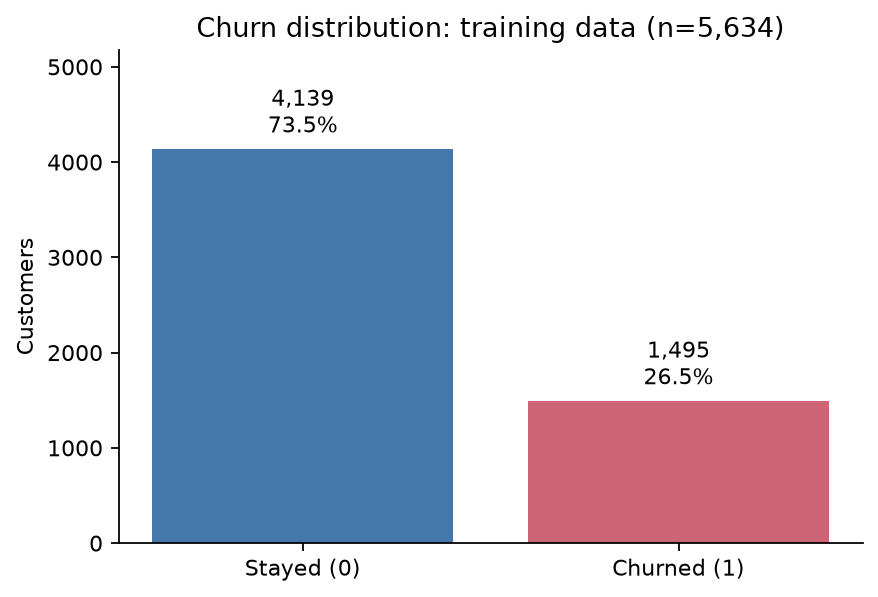

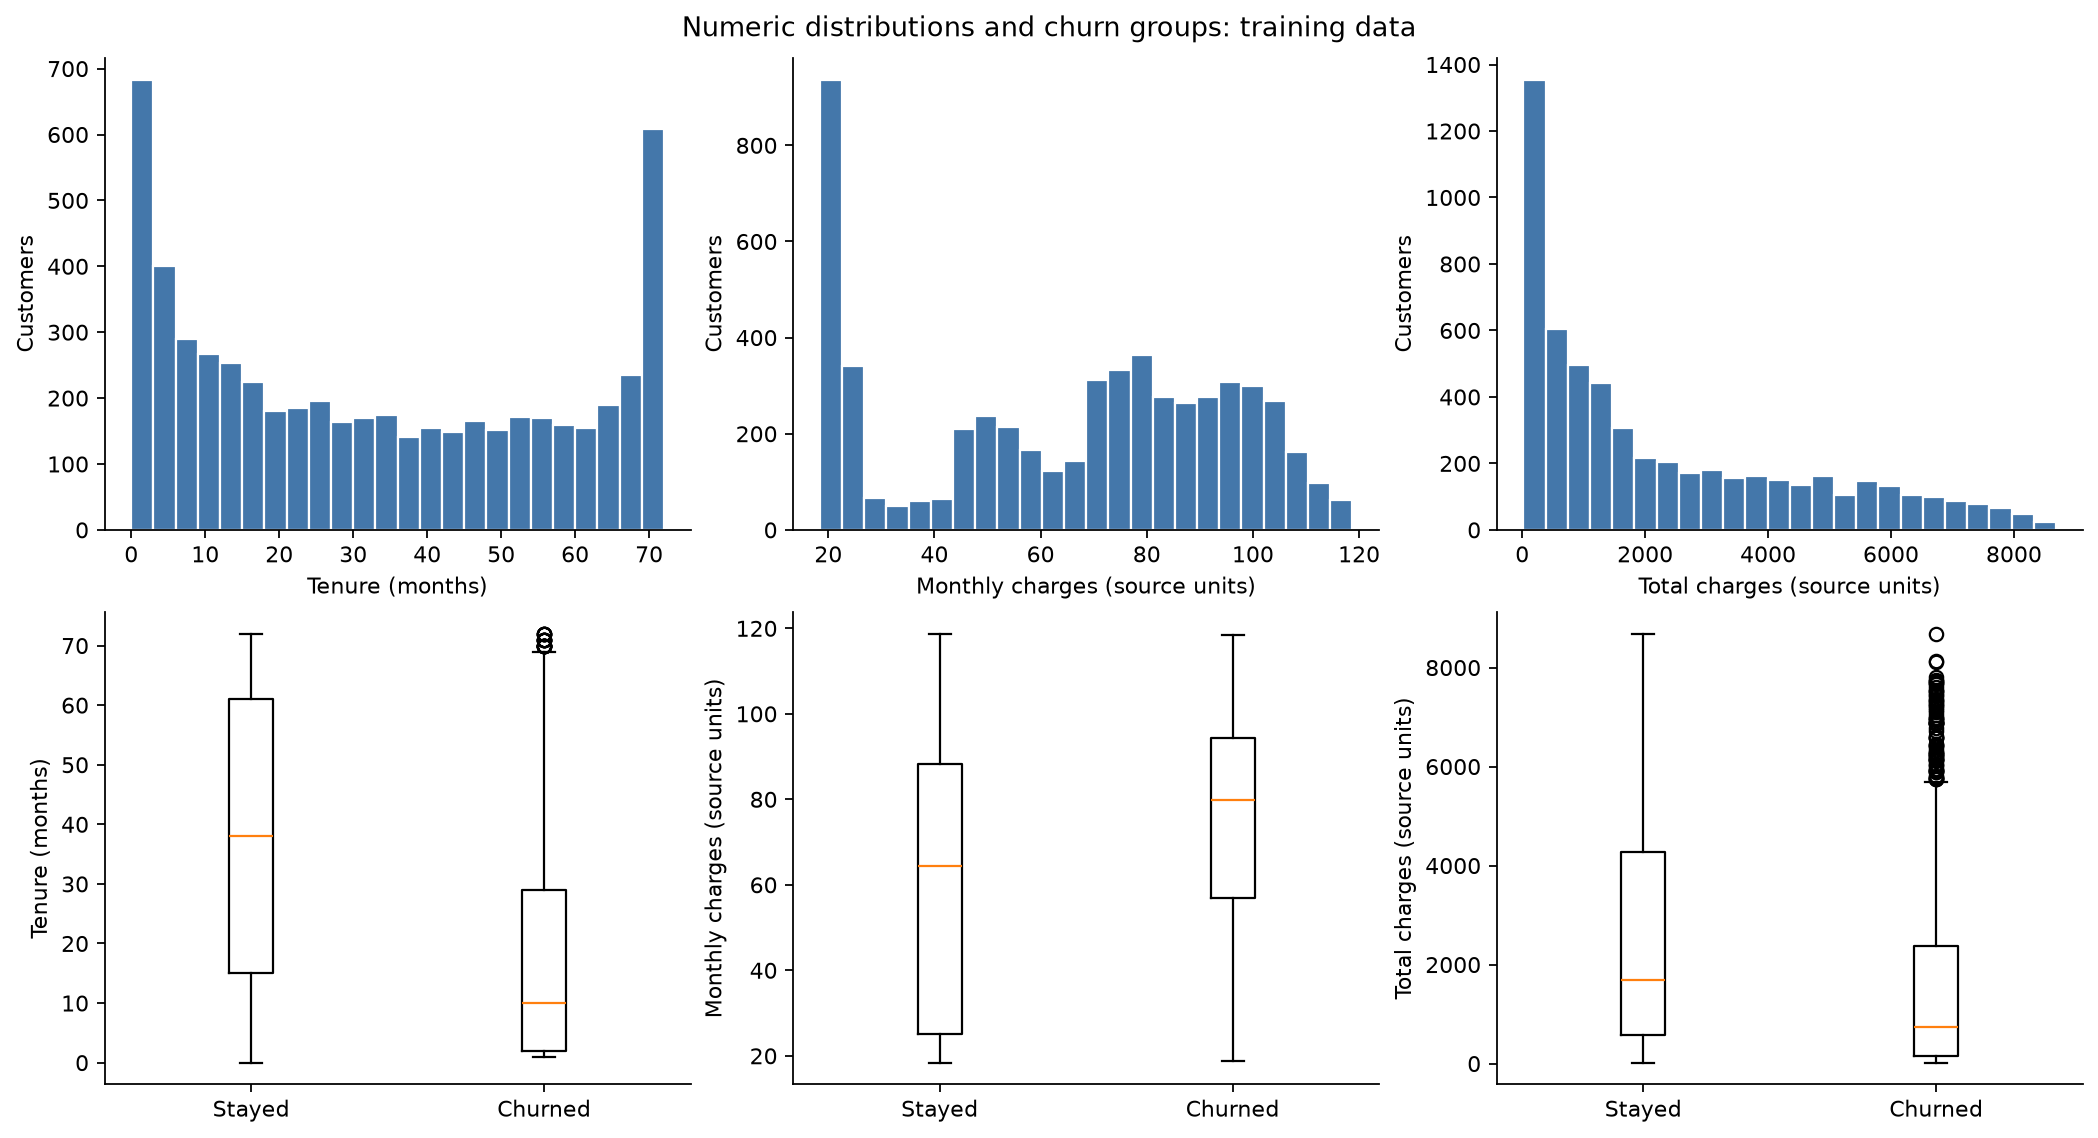

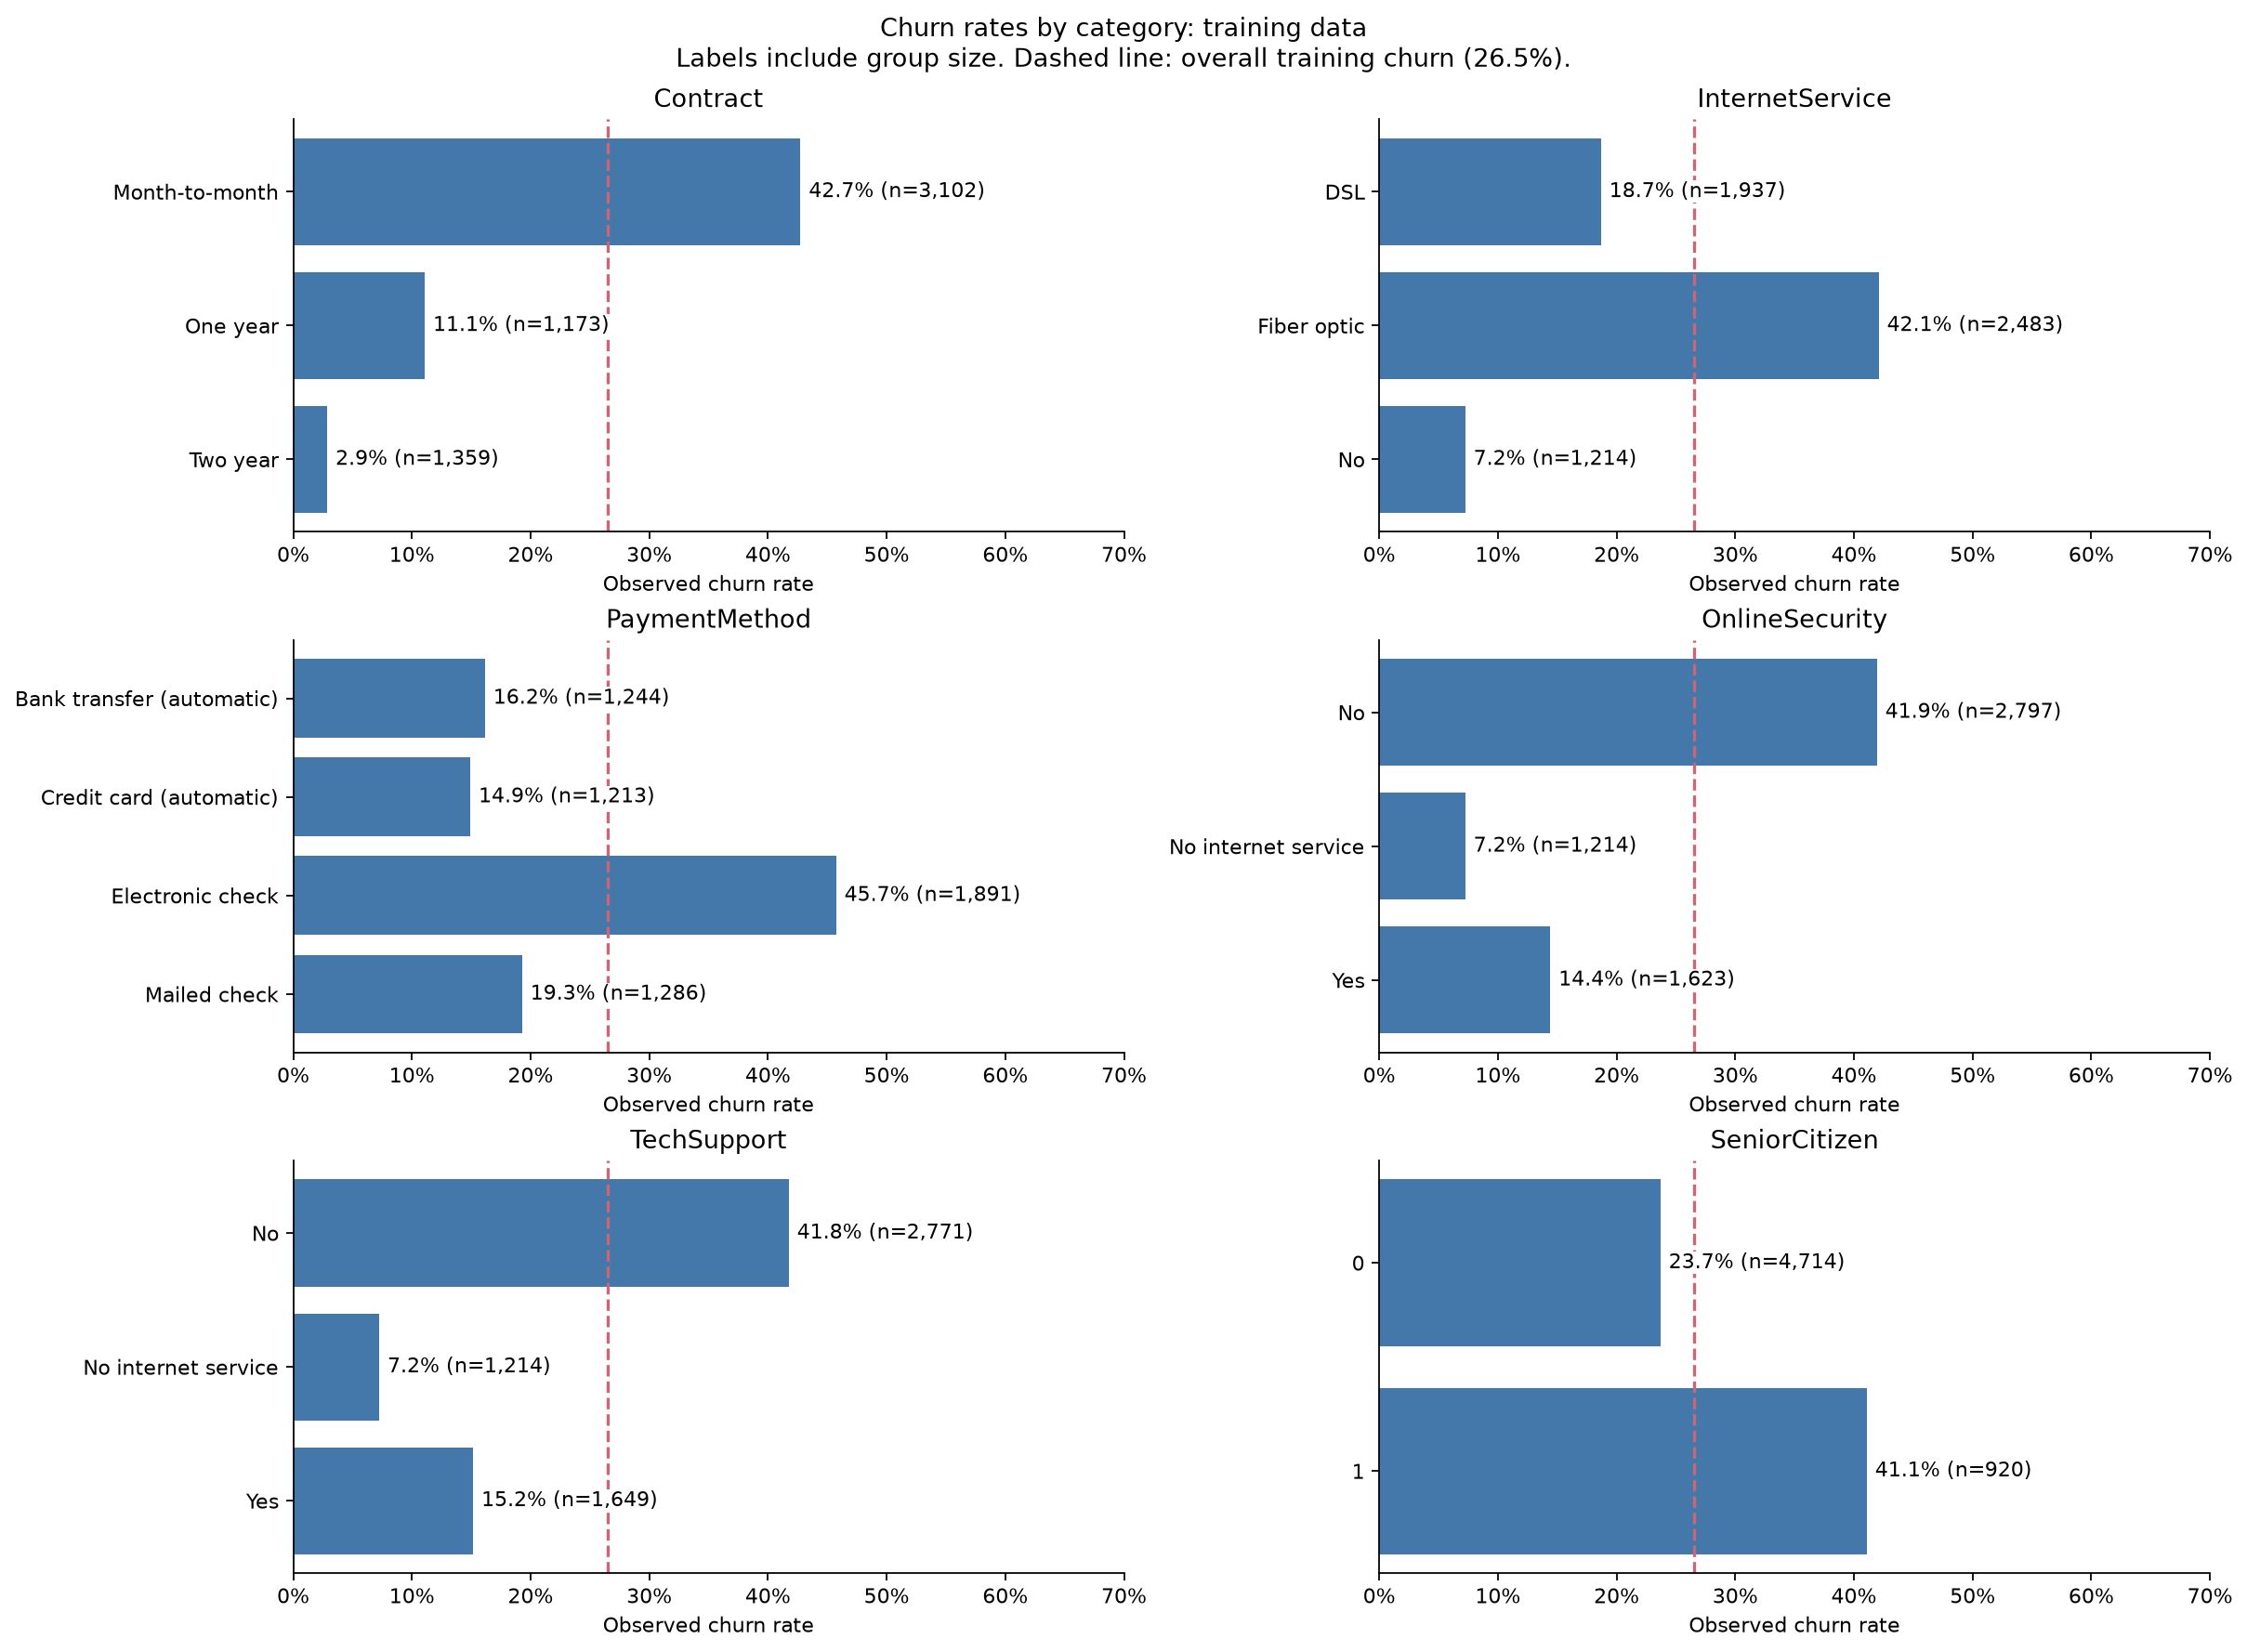

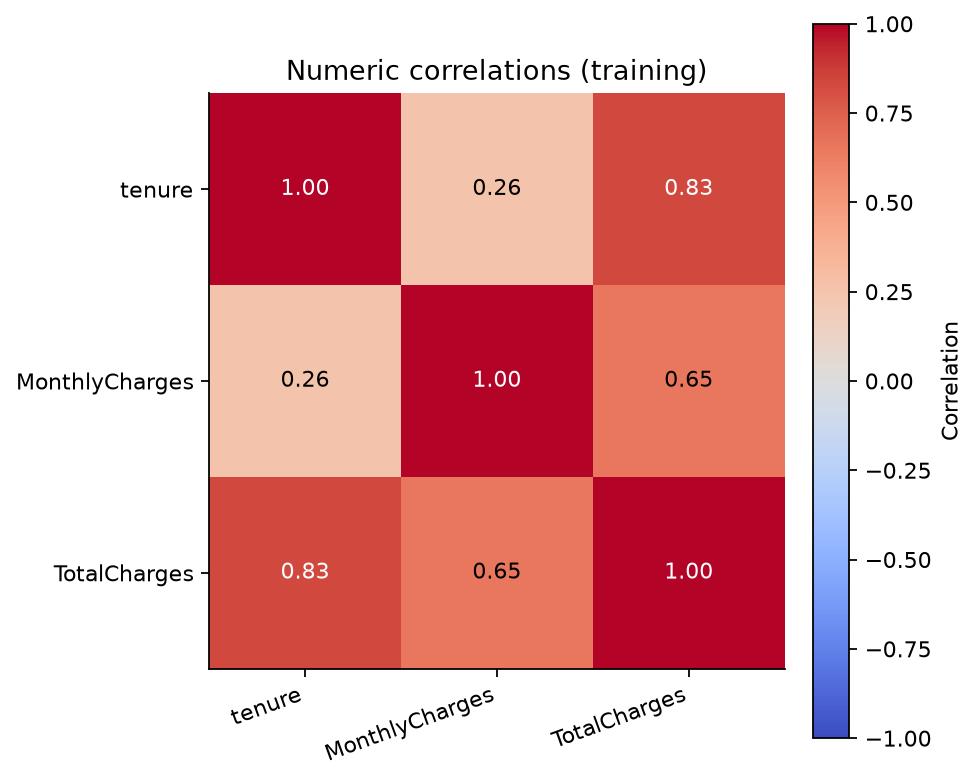

In [4]:
training = explore_data.main()
display(pd.read_csv(ROOT / "results/eda/numeric_summary.csv"))
display(pd.read_csv(ROOT / "results/eda/categorical_churn_rates.csv").query(
    "feature == 'Contract'"
))
for filename in [
    "churn_distribution.png", "numeric_distributions.png",
    "categorical_churn_rates.png", "numeric_correlations.png",
]:
    display(Image(filename=str(ROOT / "results/eda/figures" / filename)))

## Explain the findings and limitations

The following account is generated from measured training summaries. Keep
model scores, development ethics actions and proposed deployment safeguards
separate in the final report.

In [5]:
findings = (ROOT / "results/eda/EDA.md").read_text(encoding="utf-8")
display(Markdown(findings.split("## Figures")[0]))

# Dataset inspection and EDA findings

Analysis date: 10 November 2026. These are measured descriptive results and AI interpretations, not model evaluation scores. Feature-to-target analysis uses only the 5,634 training records. The 1,409 reserved test records have not been used for EDA.

## Measured findings

- Training contains 1,495 churned customers (26.54%) and 4,139 who stayed. The majority-class training proportion is 73.46%. Accuracy alone could conceal missed churners.
- Month-to-month customers have an observed churn rate of 42.75%, compared with 11.08% for one-year and 2.87% for two-year contracts. Group sizes and numerators appear in categorical_churn_rates.csv.
- Median tenure is 10 months among churned customers and 38 months among those who stayed.
- Median monthly charges are 79.95 among churned customers and 64.40 among those who stayed, in the source's charge units.
- There are 8 missing total-charge values in training. Histograms, boxplots and numeric summaries omit missing values for that field; group denominators remain the full category counts.
- Tenure and TotalCharges have Pearson correlation 0.829 in training, calculated on observed pairs.

## Interpretation and preparation decisions

Contract and tenure show associations with churn in this training sample. These comparisons do not establish that a contract change or retention offer would prevent churn. Monthly and accumulated charges measure different aspects of the account, and accumulated charges are related to tenure. Retain all three numeric predictors initially and assess the models with training cross-validation.

Keep the original data unchanged. Retain distinct customer IDs even where profiles match. Exclude the identifier from predictors and encode the target separately. Preserve valid service-absence categories. Keep SeniorCitizen categorical. Numeric scaling is planned for KNN and logistic regression; it must be fitted inside their training pipelines.

The full-file audit found 11 blank total-charge strings, all on records with zero tenure. This pattern does not prove the correct replacement value. Retain them as missing and plan median imputation within training folds. Extreme values in the displayed distributions are retained because no verified data error has been established.

## Ethics and limits

Publish aggregate tables and code; keep customer-level records local. Gender and the senior-citizen indicator need scrutiny when evaluating subgroup errors later. Observed group churn rates alone do not establish model fairness. Consider whether these fields are appropriate for the intended use and explain that decision before deployment.

Kaggle describes the target as customers who left within the last month. This is a static sample without verified observation dates or prospective follow-up. Predictor availability at decision time remains an assumption. Later test performance will describe this held-out sample, not prove performance on future customers. The source metadata does not establish a representative deployment population.

## Evidence and next step

Tables and four figures in this folder are generated by explore_data.py. The source checksum, split seed and partition hashes are recorded in results/split_summary.json. The data dictionary and provenance are in data/DATASET.md.

Next: construct leakage-safe model pipelines, fit all three baseline classifiers, and agree how the brief's undefined "both model experimental settings" should be interpreted. No models, performance scores or post-deployment monitoring have been implemented in this milestone.



## Before moving to models

Explain why the ID is excluded, why blank total charges have not been replaced
with zero, and why model selection must use training data. Explain what the
contract comparison shows and what it cannot show.

Next work: preprocessing pipelines and KNN, logistic regression and random
forest baselines. The meaning of "both model experimental settings" still
needs confirmation. This notebook does not claim demonstrated understanding
or completed viva preparation.

Sources: [specified Kaggle dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
and [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html).
See data/DATASET.md and AI_ASSISTANCE.md for provenance and assistance records.